# The Linear Model in Practice — Exercises
## Econometrics Part 2

**Instructor:** Jose Angel Garcia Sanchez  
**Institution:** Université Paris 1 Panthéon-Sorbonne  
**Course:** Econometrics (QEM 1, DU MMEF, M1 IMMAEF)

---

### Topics Covered:
1. **Multicollinearity** — Exact and near multicollinearity, VIF
2. **Handling Categories** — Dummy variables (2 and more categories, outlier dummies)
3. **Omitted Variable Bias** — Frisch-Waugh theorem
4. **Predictions in Logs** — Retransformation parameter, smearing estimator
5. **Influential Observations** — Leverage, outliers, studentized residuals, Cook's distance, DFbeta, DFfit

> **Instructions:** Complete each code cell by replacing `# YOUR CODE HERE` with your solution. Cells marked with `# TODO` indicate what you need to implement.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import OLSInfluence, variance_inflation_factor

np.random.seed(42)
sns.set_style("whitegrid")
%matplotlib inline

---
## Exercise 1: Multicollinearity

Multicollinearity arises when one explanatory variable is (almost) equal to a linear combination of other explanatory variables.

- **Exact multicollinearity**: a variable is an *exact* linear combination of others → $X$ is not full rank → $(X'X)^{-1}$ does not exist → OLS cannot be computed.
- **Near multicollinearity**: variables are very strongly correlated → OLS *can* be computed, but $\hat{b}$ is very unstable (high variance).

### Part A: Exact Multicollinearity

Generate data where `income_after_tax = income_before_tax - tax` (exact linear combination) and observe what happens when you try to run OLS with all three variables.

In [3]:
# Exercise 1A: Exact multicollinearity

N = 200
np.random.seed(42)

# Generate income, tax and dependent variable
income_before_tax = np.random.normal(50, 10, N)
tax = 0.3 * income_before_tax + np.random.normal(0, 1, N)

# TODO: Create income_after_tax as an exact linear combination of the other two
# YOUR CODE HERE
income_after_tax = income_before_tax - tax

y = 3 + 2 * income_before_tax + 0.5 * tax + np.random.normal(0, 5, N)

df_multi = pd.DataFrame(
    {
        "income_before_tax": income_before_tax,
        "tax": tax,
        "income_after_tax": income_after_tax,
        "y": y,
    }
)

# TODO: Create the design matrix with all three variables + constant
# YOUR CODE HERE
X_collinear = sm.add_constant(
    df_multi[["income_before_tax", "tax", "income_after_tax"]]
)

# TODO: Check the rank of the design matrix. What do you expect?
# YOUR CODE HERE
print("Rank of the design matrix:", np.linalg.matrix_rank(X_collinear))

# TODO: Try to estimate OLS with all three variables. What happens?
# YOUR CODE
model = sm.OLS(df_multi["y"], X_collinear).fit()
print(model.summary())

Rank of the design matrix: 3
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.939
Model:                            OLS   Adj. R-squared:                  0.939
Method:                 Least Squares   F-statistic:                     1529.
Date:                Fri, 27 Feb 2026   Prob (F-statistic):          1.05e-120
Time:                        14:04:43   Log-Likelihood:                -602.12
No. Observations:                 200   AIC:                             1210.
Df Residuals:                     197   BIC:                             1220.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const    

### Part B: Near Multicollinearity

Now consider variables that are highly correlated but not exactly collinear.

**Task:** Run a Monte Carlo simulation with 500 replications. For each replication, generate $x_1$ and $x_2$ with a given correlation $\rho$, then estimate $y = b_0 + b_1 x_1 + b_2 x_2 + u$ (with true values $b_0=1, b_1=2, b_2=3$).

Do this for $\rho \in \{0, 0.5, 0.9, 0.95, 0.99, 0.999\}$.

**Questions:**
1. What happens to the **mean** of $\hat{b}_1$ as $\rho$ increases?
2. What happens to the **standard deviation** of $\hat{b}_1$ as $\rho$ increases?
3. Is the OLS estimator still unbiased under near multicollinearity?

In [5]:
# Exercise 1B: Near multicollinearity — unstable estimates

np.random.seed(42)
N = 100
b0_true, b1_true, b2_true = 1, 2, 3

correlations = [0.0, 0.5, 0.9, 0.95, 0.99, 0.999]
n_simulations = 500

results = {}
for rho in correlations:
    b1_estimates = []
    b2_estimates = []
    for _ in range(n_simulations):
        # TODO: Generate correlated x1, x2 using np.random.multivariate_normal
        # Hint: covariance matrix = [[1, rho], [rho, 1]]
        mean = [0, 0]
        cov = [[1, rho], [rho, 1]]
        X_raw = np.random.multivariate_normal(mean, cov, N)
        x1, x2 = X_raw[:, 0], X_raw[:, 1]

        # TODO: Generate y using the true parameters + noise N(0,1)
        # YOUR CODE HERE
        u = np.random.normal(0, 1, N)
        y = b0_true + b1_true * x1 + b2_true * x2 + u

        # TODO: Estimate OLS and save b1_hat and b2_hat
        X = sm.add_constant(np.column_stack([x1, x2]))
        # YOUR CODE HERE
        model = sm.OLS(y, X).fit()
        b1_estimates.append(model.params[1])
        b2_estimates.append(model.params[2])

    results[rho] = {
        "b1_mean": np.mean(b1_estimates),
        "b1_std": np.std(b1_estimates),
        "b2_mean": np.mean(b2_estimates),
        "b2_std": np.std(b2_estimates),
    }

# Display results
print(
    f"{'Correlation':>12} | {'E[b̂₁]':>8} {'Std(b̂₁)':>10} | {'E[b̂₂]':>8} {'Std(b̂₂)':>10}"
)
print("-" * 60)
for rho in correlations:
    r = results[rho]
    print(
        f"{rho:>12.3f} | {r['b1_mean']:>8.3f} {r['b1_std']:>10.3f} | {r['b2_mean']:>8.3f} {r['b2_std']:>10.3f}"
    )

print(f"\nTrue values:   b1 = {b1_true}, b2 = {b2_true}")

 Correlation |   E[b̂₁]   Std(b̂₁) |   E[b̂₂]   Std(b̂₂)
------------------------------------------------------------
       0.000 |    1.998      0.101 |    3.000      0.099
       0.500 |    2.001      0.114 |    3.009      0.117
       0.900 |    2.010      0.235 |    2.991      0.236
       0.950 |    2.020      0.320 |    2.979      0.321
       0.990 |    2.088      0.701 |    2.916      0.704
       0.999 |    1.910      2.294 |    3.093      2.295

True values:   b1 = 2, b2 = 3


### Visualize the effect of near multicollinearity

Plot the distribution of $\hat{b}_1$ across simulations for each correlation level.

/var/folders/9t/_dbsg1912_q5_0l71jrhnvlr0000gn/T/ipykernel_14731/2674771329.py:33: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
/Users/jags/Documents/GitHub/econometrics_course/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


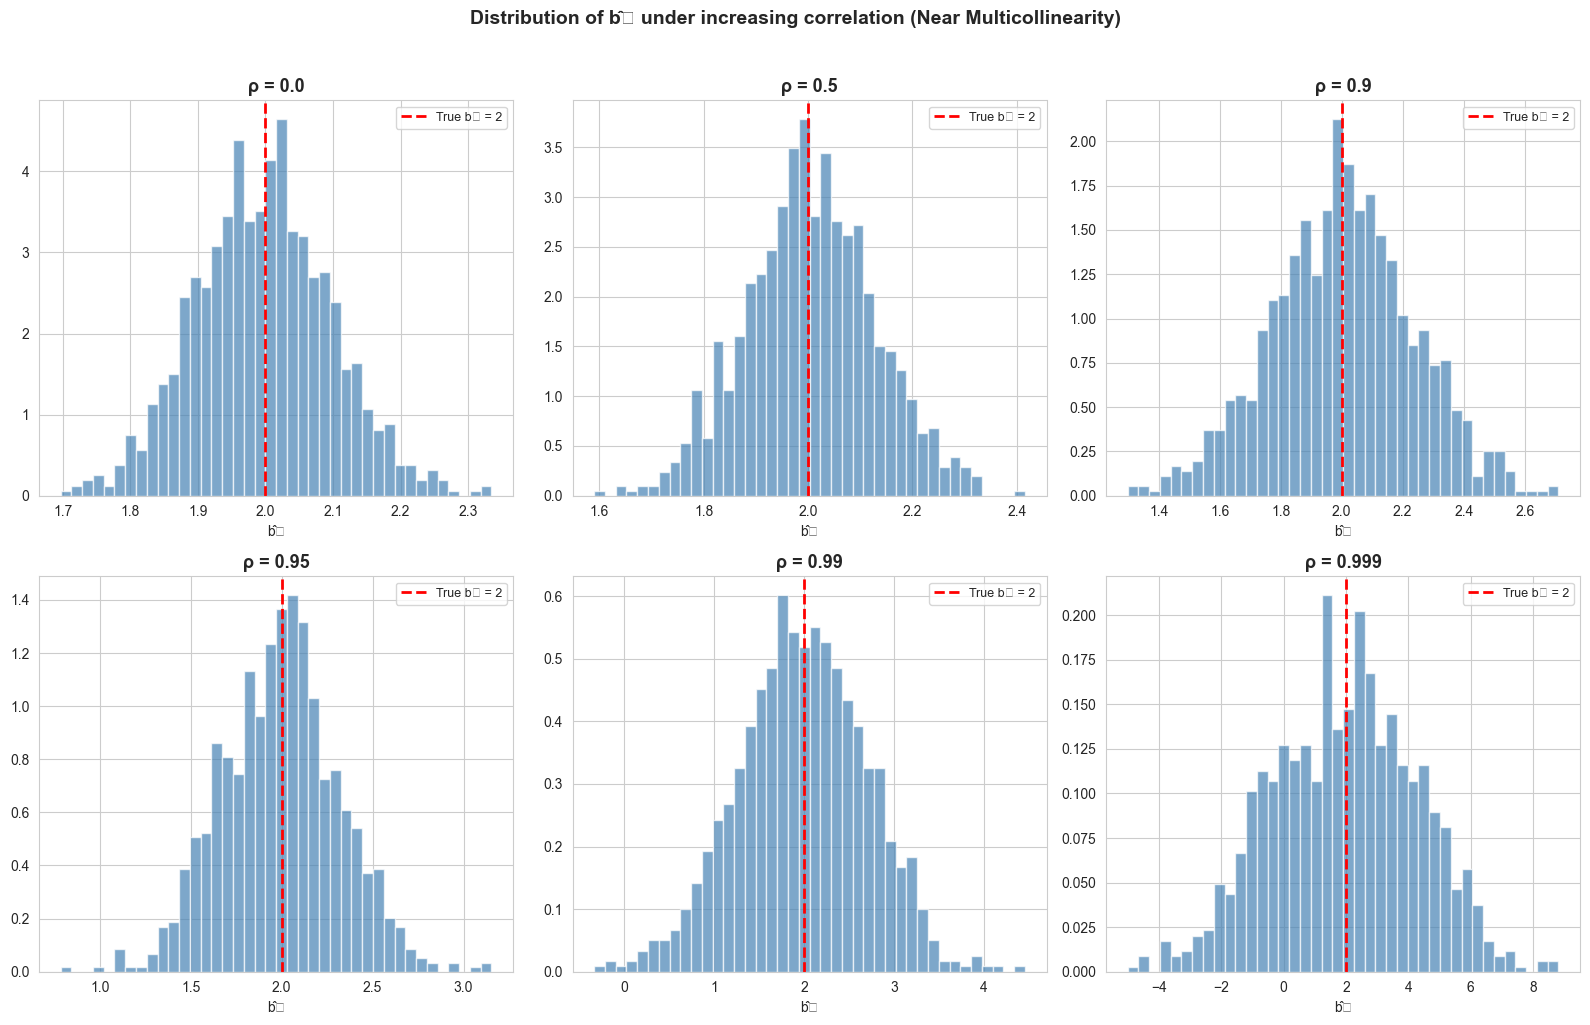

In [6]:
# Exercise 1B (cont.): Visualize distributions of b̂₁ under near multicollinearity

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
selected_corrs = [0.0, 0.5, 0.9, 0.95, 0.99, 0.999]

for idx, rho in enumerate(selected_corrs):
    ax = axes[idx // 3, idx % 3]

    # TODO: Run 1000 simulations for this correlation and collect b1 estimates
    b1_est = []
    for _ in range(1000):
        cov = [[1, rho], [rho, 1]]
        X_raw = np.random.multivariate_normal([0, 0], cov, N)
        u = np.random.normal(0, 1, N)
        y = b0_true + b1_true * X_raw[:, 0] + b2_true * X_raw[:, 1] + u
        X = sm.add_constant(X_raw)
        model = sm.OLS(y, X).fit()
        b1_est.append(model.params[1])

    # TODO: Plot histogram of b1 estimates and add a vertical line at the true value
    # YOUR CODE HERE
    ax.hist(
        b1_est, bins=40, density=True, alpha=0.7, color="steelblue", edgecolor="white"
    )
    ax.axvline(
        b1_true, color="red", linewidth=2, linestyle="--", label=f"True b₁ = {b1_true}"
    )
    ax.set_title(f"ρ = {rho}", fontsize=13, fontweight="bold")
    ax.set_xlabel("b̂₁")
    ax.legend(fontsize=9)

    ax.set_title(f"ρ = {rho}", fontsize=13, fontweight="bold")
    ax.set_xlabel("b̂₁")

plt.suptitle(
    "Distribution of b̂₁ under increasing correlation (Near Multicollinearity)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

### Part C: Variance Inflation Factor (VIF)

The VIF measures how much the variance of $\hat{b}_i$ is inflated due to multicollinearity.

**How it works:**
- Regress each $X_i$ on all other $X_j$'s, obtain $R^2_i$
- $VIF_i = \frac{1}{1 - R^2_i}$

**Interpretation:**
- $VIF_i = 1$: no correlation with other variables
- $VIF_i > 5$: high risk of multicollinearity
- $VIF_i > 10$: severe multicollinearity

**Connection to variance:** $V(\hat{b}_j) = \frac{\sigma^2}{(N-1)\widehat{Var}(X_j)} \cdot VIF_j$

**Tasks:**
1. Use `variance_inflation_factor` from `statsmodels` to compute VIF for all variables.
2. Manually compute VIF for `education` by regressing it on all other variables.

In [11]:
# Exercise 1C: Compute VIF

np.random.seed(42)
N = 500

# Generate dataset with some correlated variables
education = np.random.normal(13, 3, N)
experience = np.random.normal(15, 8, N)
experience_sq = experience**2
parent_education = 0.4 * education + np.random.normal(10, 2, N)
ability = np.random.normal(100, 15, N)

wage = (
    5
    + 1.2 * education
    + 0.3 * experience
    - 0.005 * experience_sq
    + 0.1 * parent_education
    + 0.05 * ability
    + np.random.normal(0, 5, N)
)

df_vif = pd.DataFrame(
    {
        "education": education,
        "experience": experience,
        "experience_sq": experience_sq,
        "parent_education": parent_education,
        "ability": ability,
        "wage": wage,
    }
)

# TODO: Add a constant and compute VIF for each variable using variance_inflation_factor
# Hint: variance_inflation_factor(X.values, i) gives VIF for column i
# YOUR CODE HERE
X_vif = sm.add_constant(
    df_vif[["education", "experience", "experience_sq", "parent_education", "ability"]]
)
for i in range(1, X_vif.shape[1]):
    vif_value = variance_inflation_factor(X_vif, i)
    print(vif_value)

# TODO: Manually compute VIF for 'education'
# Step 1: Regress education on all other X variables (+ constant)
# Step 2: Get R²
# Step 3: VIF = 1 / (1 - R²)
# YOUR CODE HERE

X_vif

1.2948848880292336
9.378712762166964
9.365913268486198
1.2841194943842889
1.006493026422969


,const,education,experience,experience_sq,parent_education,ability
0,1.0,14.490142,22.409420,502.182122,18.594768,111.675416
1,1.0,12.585207,30.275333,916.595796,16.883350,91.732214
2,1.0,14.943066,3.811459,14.527223,16.096487,87.727017
3,1.0,17.569090,19.503754,380.396416,15.733762,99.949383
4,1.0,12.297540,9.794859,95.939272,16.315463,97.447231
...,...,...,...,...,...,...
495,1.0,14.616730,12.751198,162.593042,19.858878,116.052254
496,1.0,9.888262,29.381492,863.272085,18.078312,99.602181
497,1.0,12.428984,20.126743,405.085779,17.388326,86.771880
498,1.0,10.373145,10.430568,108.796751,16.197383,97.553996


---
## Exercise 2: Handling Categories — Dummy Variables

Categorical variables must be encoded as **dummy variables** (0/1) before being used in regression.

### Key Rules:
- For a variable with **2 categories**: use 1 dummy (the omitted category is the **reference**)
- For a variable with **K categories**: use **K−1** dummies (to avoid the "dummy variable trap" = exact multicollinearity with the constant)
- **Never** use the original numeric coding (1, 2, 3) for unordered categories

### Part A: Dummy variable with 2 categories (Gender)

Consider a model: $wage_i = a + b \cdot education_i + c \cdot male_i + u_i$

Here $c$ represents the extra income from being male relative to being female (the reference category).

In [14]:
# Exercise 2A: Dummy variable with 2 categories

np.random.seed(42)
N = 500

education = np.random.normal(13, 3, N)
gender = np.random.binomial(1, 0.5, N)  # 1 = male, 0 = female (reference)

# True model: wage = 10 + 1.5*education + 3*male + u
wage = 10 + 1.5 * education + 3 * gender + np.random.normal(0, 4, N)

df_gender = pd.DataFrame({"wage": wage, "education": education, "male": gender})

# TODO: Estimate the model wage = b0 + b1*education + b2*male + u
# YOUR CODE HERE
X_gender = df_gender[["education", "male"]]
X_gender = sm.add_constant(X_gender)
model_gender = sm.OLS(df_gender["wage"], X_gender).fit()

# TODO: Interpret each coefficient. What does the coefficient on 'male' represent?
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   wage   R-squared:                       0.576
Model:                            OLS   Adj. R-squared:                  0.575
Method:                 Least Squares   F-statistic:                     338.1
Date:                Fri, 27 Feb 2026   Prob (F-statistic):           1.98e-93
Time:                        14:42:16   Log-Likelihood:                -1401.0
No. Observations:                 500   AIC:                             2808.
Df Residuals:                     497   BIC:                             2821.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         10.1205      0.837     12.093      0.0

### Visualize the parallel regression lines

With a dummy variable, we get **two parallel lines** (same slope, different intercept).

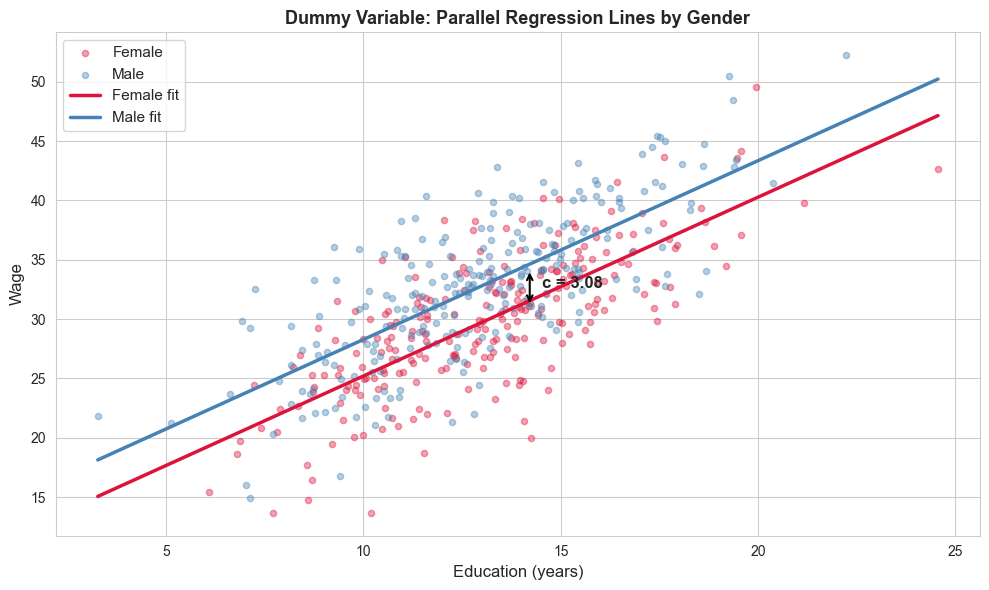

In [15]:
# Exercise 2A (cont.): Visualize parallel regression lines

fig, ax = plt.subplots(figsize=(10, 6))

# TODO: Scatter plot data
colors = {0: "crimson", 1: "steelblue"}
labels = {0: "Female", 1: "Male"}
for g in [0, 1]:
    mask = df_gender["male"] == g
    ax.scatter(
        df_gender.loc[mask, "education"],
        df_gender.loc[mask, "wage"],
        alpha=0.4,
        color=colors[g],
        label=labels[g],
        s=20,
    )

# TODO: Plot fitted lines
x_range = np.linspace(df_gender["education"].min(), df_gender["education"].max(), 100)
b = model_gender.params
ax.plot(
    x_range,
    b["const"] + b["education"] * x_range,
    color="crimson",
    linewidth=2.5,
    label="Female fit",
)
ax.plot(
    x_range,
    b["const"] + b["education"] * x_range + b["male"],
    color="steelblue",
    linewidth=2.5,
    label="Male fit",
)

# TODO: Annotate the gap
mid_x = np.mean(x_range)
y_f = b["const"] + b["education"] * mid_x
y_m = y_f + b["male"]
ax.annotate(
    "",
    xy=(mid_x + 0.3, y_m),
    xytext=(mid_x + 0.3, y_f),
    arrowprops=dict(arrowstyle="<->", color="black", lw=1.5),
)
ax.text(
    mid_x + 0.6, (y_f + y_m) / 2, f"c = {b['male']:.2f}", fontsize=12, fontweight="bold"
)

ax.set_xlabel("Education (years)", fontsize=12)
ax.set_ylabel("Wage", fontsize=12)
ax.set_title(
    "Dummy Variable: Parallel Regression Lines by Gender",
    fontsize=13,
    fontweight="bold",
)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

### Part B: Dummy variables with more than 2 categories

When a categorical variable has K > 2 categories, we need K−1 dummy variables. The omitted category serves as the **reference group**.

**Example:** Explain life satisfaction by income and environment type (*big city*, *small city*, *rural*).

**Tasks:**
1. First, run the **wrong** regression using the original numeric coding (1, 2, 3).
2. Then, create proper dummy variables and run the **correct** regression.
3. Explain why including ALL K dummies causes exact multicollinearity ("dummy variable trap").

In [21]:
# Exercise 2B: Dummy variables with 3+ categories

np.random.seed(42)
N = 600

income = np.random.normal(40, 10, N)
environment = np.random.choice([1, 2, 3], N, p=[0.4, 0.35, 0.25])

# True model: life_satisfaction = 5 + 0.1*income + 3*(big_city) + 1.5*(small_city) + u
life_sat = (
    5
    + 0.1 * income
    + 3 * (environment == 1)
    + 1.5 * (environment == 2)
    + np.random.normal(0, 2, N)
)

df_env = pd.DataFrame(
    {"life_satisfaction": life_sat, "income": income, "environment": environment}
)
df_env["env_label"] = df_env["environment"].map(
    {1: "Big city", 2: "Small city", 3: "Rural"}
)

# TODO: WRONG approach — use the numeric coding (1,2,3) directly in the regression
# What is the problem with this?
# YOUR CODE HERE
X_wrong = sm.add_constant(df_env[["environment", "income"]])
model_wrong = sm.OLS(df_env["life_satisfaction"], X_wrong).fit()


# TODO: CORRECT approach — create dummy variables using pd.get_dummies
# Use 'Rural' as the reference category (drop it)
# YOUR CODE HERE

dummies = pd.get_dummies(df_env["env_label"], drop_first=True, dtype=int)
X_correct = sm.add_constant(df_env[["income"]].join(dummies))
model_correct = sm.OLS(df_env["life_satisfaction"], X_correct).fit()

# TODO: Explain why including ALL K dummies (Big city + Small city + Rural)
# together with a constant causes exact multicollinearity
# YOUR CODE HERE

print(model_wrong.summary())
print(model_correct.summary())

                            OLS Regression Results                            
Dep. Variable:      life_satisfaction   R-squared:                       0.372
Model:                            OLS   Adj. R-squared:                  0.370
Method:                 Least Squares   F-statistic:                     177.1
Date:                Fri, 27 Feb 2026   Prob (F-statistic):           4.20e-61
Time:                        14:58:34   Log-Likelihood:                -1280.3
No. Observations:                 600   AIC:                             2567.
Df Residuals:                     597   BIC:                             2580.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           9.4925      0.408     23.264      

### Part C: Dummy variables for outlier events

Dummy variables can handle outlier observations (e.g., a shock event in time series) **without deleting** them.

**Task:** Estimate a time series model of life expectancy on doctors per capita, where year 25 experienced a pandemic shock. Compare the model with and without a shock dummy.

In [ ]:
# Exercise 2C: Dummy for outlier events

np.random.seed(42)
T = 50

doctors = np.cumsum(np.random.normal(0.5, 0.3, T)) + 10
life_exp = 60 + 0.8 * doctors + np.random.normal(0, 1.5, T)

# Introduce a shock at year 25 (e.g., pandemic)
shock_year = 25
life_exp[shock_year] -= 12

df_ts = pd.DataFrame({"year": range(T), "doctors": doctors, "life_exp": life_exp})

# TODO: Create a dummy variable D_shock = 1 if year == 25, 0 otherwise
# YOUR CODE HERE


# TODO: Estimate model WITHOUT the dummy
# YOUR CODE HERE


# TODO: Estimate model WITH the shock dummy
# YOUR CODE HERE


# TODO: Compare the two models (coefficients, R²) and interpret the dummy coefficient
# YOUR CODE HERE

---
## Exercise 3: Omitted Variable Bias

Omitting a relevant variable from the model leads to **biased** estimates of all coefficients.

### The Frisch-Waugh Theorem

Consider two models:
1. $y = Xb_{(i)} + Zc + u$ (full model)
2. $M_Z y = M_Z X b_{(ii)} + M_Z u$ (partialled-out model, where $M_Z = I - Z(Z'Z)^{-1}Z'$)

The theorem states: $\hat{b}_{(i)} = \hat{b}_{(ii)}$

**Consequence:** Estimating with both $X$ and $Z$ vs. with $X$ alone will NOT give the same $\hat{b}$, unless $X'Z = 0$ (completely uncorrelated), which is very unlikely.

### Part A: Demonstrate omitted variable bias

**True model:** $wage = 5 + 2 \cdot education + 3 \cdot ability + u$

where education and ability are **correlated** (smarter people tend to get more education).

**Tasks:**
1. Estimate the full (correct) model with both variables.
2. Estimate the short (misspecified) model omitting ability.
3. Compare the coefficient on education. Is it biased? In which direction? Why?

In [ ]:
# Exercise 3A: Omitted variable bias

np.random.seed(42)
N = 1000

# True model: wage = 5 + 2*education + 3*ability + u
education = np.random.normal(13, 3, N)
ability = np.random.normal(100, 15, N)

# Make education and ability correlated
education = education + 0.1 * (ability - 100)

wage = 5 + 2 * education + 3 * ability + np.random.normal(0, 10, N)

df_ov = pd.DataFrame({"wage": wage, "education": education, "ability": ability})

# TODO: Estimate the full model (wage ~ education + ability)
# YOUR CODE HERE


# TODO: Estimate the short model (wage ~ education), omitting ability
# YOUR CODE HERE


# TODO: Compare the education coefficient in both models
# Is it biased in the short model? Why?
# YOUR CODE HERE

### Simulation: Visualize the bias across many samples

Run a Monte Carlo to show the distribution of $\hat{b}_1$ in the full vs. short model.

In [ ]:
# Exercise 3A (cont.): Monte Carlo for OVB

n_sim = 2000
N = 200
b1_full = []
b1_short = []

for _ in range(n_sim):
    edu = np.random.normal(13, 3, N)
    abil = np.random.normal(100, 15, N)
    edu = edu + 0.1 * (abil - 100)
    w = 5 + 2 * edu + 3 * abil + np.random.normal(0, 10, N)

    # TODO: Estimate full model and save b1
    # YOUR CODE HERE

    # TODO: Estimate short model and save b1
    # YOUR CODE HERE


# TODO: Plot histograms of b1_full and b1_short on the same graph
# Add a vertical line at the true b1 = 2
# YOUR CODE HERE

### Part B: Verify the Frisch-Waugh Theorem

**Steps (partialling-out procedure):**
1. Regress `education` on `constant + ability` → get residuals $\tilde{X}$
2. Regress `wage` on `constant + ability` → get residuals $\tilde{y}$
3. Regress $\tilde{y}$ on $\tilde{X}$ (no constant)

**Verify** that the coefficient from step 3 equals $\hat{b}_1$ from the full model.

In [ ]:
# Exercise 3B: Verify the Frisch-Waugh theorem

# TODO: Step 1 — Regress education on (constant + ability), get residuals
# YOUR CODE HERE
resid_education = None

# TODO: Step 2 — Regress wage on (constant + ability), get residuals
# YOUR CODE HERE
resid_wage = None

# TODO: Step 3 — Regress resid_wage on resid_education (no constant!)
# YOUR CODE HERE
b1_from_FW = None

# Compare with the full model coefficient
b1_from_full = model_full.params["education"]

print("Frisch-Waugh Theorem Verification:")
print("=" * 50)
print(f"  b̂₁ from full model:       {b1_from_full:.8f}")
print(f"  b̂₁ from Frisch-Waugh:     {b1_from_FW}")

### Part C: Side effect — Centered variables

A consequence of the FW theorem: estimating $y_t = a + b \cdot x_t + u_t$ with or without centering (replacing $y_i$ by $y_i - \bar{y}$) gives the same $\hat{b}$.

**Task:** Verify this numerically.

In [ ]:
# Exercise 3C: Centering and the constant

# TODO: Estimate wage ~ education with a constant
# YOUR CODE HERE


# TODO: Center both variables and estimate without a constant
# YOUR CODE HERE


# TODO: Compare the slope coefficients


---
## Exercise 4: Predictions in Logs

### Advantages of using logs:
1. Can make residuals look more "normal"
2. Can reduce heteroskedasticity
3. Parameters can be interpreted as percentages or elasticities

### The retransformation problem

If we estimate $\log(y_i) = a + bx_i + u_i$, we **cannot** simply exponentiate the prediction to get back to levels.

Since $y_i = \exp(a + bx_i) \cdot \exp(u_i)$, the prediction is:

$$\hat{y}_i = \exp(\hat{a} + \hat{b}x_i) \cdot \hat{\Psi}$$

where $\hat{\Psi}$ is the **retransformation parameter**:
- If $u \sim N(0, \sigma^2)$: $\hat{\Psi} = \exp(\hat{\sigma}^2 / 2)$
- Non-parametric (Duan's smearing): $\hat{\Psi} = \frac{1}{N}\sum \exp(\hat{u}_i)$

**Tasks:**
1. Estimate a log-linear wage model.
2. Compare three ways to predict wages in levels: naive (just exp), normal retransformation, and Duan's smearing.
3. Which method gives the best average prediction?

In [ ]:
# Exercise 4: Predictions in logs

np.random.seed(42)
N = 500

education = np.random.normal(13, 3, N)
education = np.clip(education, 5, 22)

# True model: log(wage) = 1.5 + 0.08*education + u, u ~ N(0, 0.3²)
sigma_u = 0.3
u = np.random.normal(0, sigma_u, N)
log_wage = 1.5 + 0.08 * education + u
wage = np.exp(log_wage)

df_log = pd.DataFrame({"education": education, "wage": wage, "log_wage": log_wage})

# TODO: Estimate the log model: log(wage) = a + b*education + u
# YOUR CODE HERE


# TODO: Method 1 — Naive prediction (just exponentiate the fitted values)
# YOUR CODE HERE
wage_pred_naive = None

# TODO: Method 2 — Normal retransformation: exp(fitted) * exp(σ̂²/2)
# Hint: σ̂² = Σ(residuals²) / (N - 2)
# YOUR CODE HERE
wage_pred_normal = None

# TODO: Method 3 — Duan's smearing: exp(fitted) * mean(exp(residuals))
# YOUR CODE HERE
wage_pred_smearing = None

# Compare average predictions with average observed wage
print("Average predictions vs. average observed wage:")
print(f"  Observed mean wage:          {df_log['wage'].mean():.2f}")
print(
    f"  Naive (exp only):            {np.mean(wage_pred_naive) if wage_pred_naive is not None else '???'}"
)
print(
    f"  Normal retransformation:     {np.mean(wage_pred_normal) if wage_pred_normal is not None else '???'}"
)
print(
    f"  Duan's smearing:             {np.mean(wage_pred_smearing) if wage_pred_smearing is not None else '???'}"
)

### Visualize predictions and residuals

In [ ]:
# Exercise 4 (cont.): Visualize predictions and check normality of residuals

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# TODO: Left plot — scatter observed wages + plot all three prediction methods
# YOUR CODE HERE


# TODO: Right plot — histogram of log-model residuals, overlay normal density
# YOUR CODE HERE


plt.tight_layout()
plt.show()

---
## Exercise 5: Influential Observations

Not all observations are equal in OLS. The slope estimator can be decomposed as:

$$\hat{b}_1 = \sum p_i \frac{(y_i - \bar{y})}{(x_i - \bar{x})} \quad \text{where } p_i = \frac{(x_i - \bar{x})^2}{\sum(x_j - \bar{x})^2}$$

Observations with extreme $x$ values get more weight ($p_i$ is larger).

### Key Concepts:
- **Outlier**: large residual (poor fit)
- **High leverage**: $x_i$ far from $\bar{x}$ → pulls regression line toward itself
- **Influential**: if removed, changes estimated coefficients significantly

### Part A: Visual demonstration

Observe how different types of unusual observations affect the regression line.

In [ ]:
# Exercise 5A: Visual demonstration of outlier types

np.random.seed(42)
N = 50
x_base = np.random.uniform(2, 8, N)
y_base = 2 + 1.5 * x_base + np.random.normal(0, 1, N)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

scenarios = [
    ("No outlier (baseline)", x_base, y_base),
    (
        "Outlier (large residual, low leverage)",
        np.append(x_base, 5),
        np.append(y_base, 20),
    ),
    (
        "High leverage, NOT influential\n(on the regression line)",
        np.append(x_base, 20),
        np.append(y_base, 2 + 1.5 * 20),
    ),
    (
        "High leverage AND influential\n(far from regression line)",
        np.append(x_base, 20),
        np.append(y_base, -5),
    ),
]

for ax, (title, x, y) in zip(axes.flat, scenarios):
    # TODO: Estimate OLS for each scenario and plot:
    # - scatter of base data (blue) + special point in red
    # - fitted line (orange)
    # - baseline fit (gray dashed) for comparison
    # YOUR CODE HERE

    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_xlim(-1, 22)
    ax.set_ylim(-8, 35)

plt.suptitle(
    "Types of unusual observations in regression", fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

### Part B: The Hat Matrix and Leverage

The predicted values are $\hat{y} = P_X y$ where $P_X = X(X'X)^{-1}X'$ (the "hat" matrix).

The diagonal element $h_i$ measures leverage:
- $0 \leq h_i \leq 1$, average $\bar{h} = k/N$
- For simple regression: $h_i = \frac{1}{N} + \frac{(x_i - \bar{x})^2}{\sum(x_j - \bar{x})^2}$
- $V(\hat{u}_i) = \sigma^2(1 - h_i)$ → higher leverage = smaller residual variance

**Tasks:**
1. Compute leverage values using `OLSInfluence`.
2. Verify by computing them manually for the simple regression case.
3. Identify high-leverage observations.

In [ ]:
# Exercise 5B: Compute leverage (hat values)

np.random.seed(42)
N = 100

education = np.random.normal(13, 3, N)
# Add a few special points
education_ext = np.append(education, [2, 25, 26])
wage_ext = np.append(
    10 + 2 * education + np.random.normal(0, 4, N),
    [10 + 2 * 2 + 1, 10 + 2 * 25, 10 + 2 * 26 - 20],  # last one is influential
)
N_ext = len(education_ext)

X = sm.add_constant(education_ext)
model = sm.OLS(wage_ext, X).fit()
influence = OLSInfluence(model)

# TODO: Get leverage values from OLSInfluence
# Hint: influence.hat_matrix_diag
# YOUR CODE HERE
leverage = None

# TODO: Compute average leverage h̄ = k/N
# YOUR CODE HERE
h_bar = None

# TODO: Manually compute leverage for simple regression
# h_i = 1/N + (x_i - x̄)² / Σ(x_j - x̄)²
# YOUR CODE HERE
h_manual = None

# TODO: Compare manual vs statsmodels values
# YOUR CODE HERE


# TODO: Identify high-leverage observations (h_i > h̄)
# YOUR CODE HERE

### Part C: Studentized Residuals

Raw residuals don't account for differences in leverage. The **studentized residuals** correct for this:

$$rstud_i = \frac{\hat{u}_i}{\hat{\sigma}\sqrt{1 - h_i}}$$

Observations with $|rstud_i| > 2$ are typically considered outliers.

**Task:** Compute studentized residuals and create diagnostic plots (raw residuals, studentized residuals, leverage).

In [ ]:
# Exercise 5C: Studentized residuals

# TODO: Get studentized residuals from OLSInfluence
# Hint: influence.resid_studentized_internal
# YOUR CODE HERE
rstud = None

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# TODO: Plot 1 — Raw residuals vs education
# YOUR CODE HERE


# TODO: Plot 2 — Studentized residuals vs education
# Add horizontal lines at ±2
# Highlight outliers (|rstud| > 2) in red
# YOUR CODE HERE


# TODO: Plot 3 — Leverage values
# Add horizontal line at h̄
# YOUR CODE HERE


plt.tight_layout()
plt.show()

### Part D: Influence Measures

| Measure | What it measures | Cutoff |
|---------|-----------------|--------|
| **Leverage** $h_i$ | How extreme is $x_i$? | $h_i > k/N$ |
| **DFbeta** | Change in $\hat{b}_k$ when obs $i$ removed | $|DFbeta| > 2$ or $2/\sqrt{N}$ |
| **DFfit** | Change in $\hat{y}_i$ when obs $i$ removed | $|DFfit| > 2$ or $2\sqrt{k/N}$ |
| **Cook's D** | Overall influence on all coefficients | $D_i > 1$ |
| **Covratio** | Change in covariance matrix determinant | $|covratio - 1| > 3k/N$ |

**Tasks:**
1. Compute all influence measures.
2. Identify influential observations using the cutoffs.
3. Create diagnostic plots (Cook's distance, DFbetas, DFfits).
4. Re-estimate the model without the most influential observation and compare.

In [ ]:
# Exercise 5D: Influence measures

# TODO: Compute DFbetas, Cook's distance, DFfits from OLSInfluence
# Hints: influence.dfbetas, influence.cooks_distance[0], influence.dffits[0]
# YOUR CODE HERE


# Cutoffs
dfbeta_cutoff = 2 / np.sqrt(N_ext)
dffit_cutoff = 2 * np.sqrt(k / N_ext)
cooks_cutoff = 1.0

# TODO: Print a summary table of potentially influential observations
# YOUR CODE HERE

In [ ]:
# Exercise 5D (cont.): Diagnostic plots

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# TODO: Plot 1 — Residuals vs Leverage
# YOUR CODE HERE


# TODO: Plot 2 — Cook's distance (stem plot)
# YOUR CODE HERE


# TODO: Plot 3 — DFbetas for the slope coefficient (stem plot)
# YOUR CODE HERE


# TODO: Plot 4 — DFfits (stem plot)
# YOUR CODE HERE


plt.suptitle("Influence Diagnostics", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Part E: Effect of removing the most influential observation

In [ ]:
# Exercise 5E: Remove most influential observation and re-estimate

# TODO: Find the observation with the highest Cook's distance
# YOUR CODE HERE
most_influential = None

# TODO: Re-estimate the model without this observation
# YOUR CODE HERE


# TODO: Compare coefficients (full sample vs. reduced sample)
# YOUR CODE HERE

---
## Summary and Key Takeaways

### 1. Multicollinearity
- **Exact**: prevents OLS computation (singular $X'X$). Solution: remove redundant variable.
- **Near**: inflates variance of estimates. Detect with **VIF** (threshold: VIF > 5).
- Don't remove variables just because of moderate VIF → risk of omitted variable bias.

### 2. Dummy Variables
- For K categories → use K−1 dummies + reference group.
- Never use original numeric codes for unordered categories.
- Can also capture outlier events (shocks) without deleting data.

### 3. Omitted Variable Bias
- Leaving out a relevant variable biases ALL coefficients.
- **Frisch-Waugh theorem**: the coefficient on $X$ in a multiple regression equals the coefficient from regressing the "partialled out" $y$ on the "partialled out" $X$.
- Bias disappears only if omitted and included variables are uncorrelated ($X'Z = 0$), which is rare.

### 4. Predictions in Logs
- Cannot simply exponentiate log predictions to get level predictions.
- Need retransformation parameter: $\hat{\Psi} = \exp(\hat{\sigma}^2/2)$ (normal case) or Duan's smearing estimator.

### 5. Influential Observations
- **Leverage** ($h_i$): measures how extreme $x_i$ is.
- **Studentized residuals**: residuals adjusted for leverage.
- **DFbeta/DFfit/Cook's distance**: measure impact of removing an observation.
- High leverage is necessary but not sufficient for influence.